In [80]:
import sys
sys.path.append('../')

import numpy as np
from joblib import Parallel, delayed
import pickle

from weighted_conformal_clustering.utils import WeightedConformalClustering, SpectralGMM, soft_predict, gen_moons3, label_alignment

from sklearn.metrics import adjusted_rand_score

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec

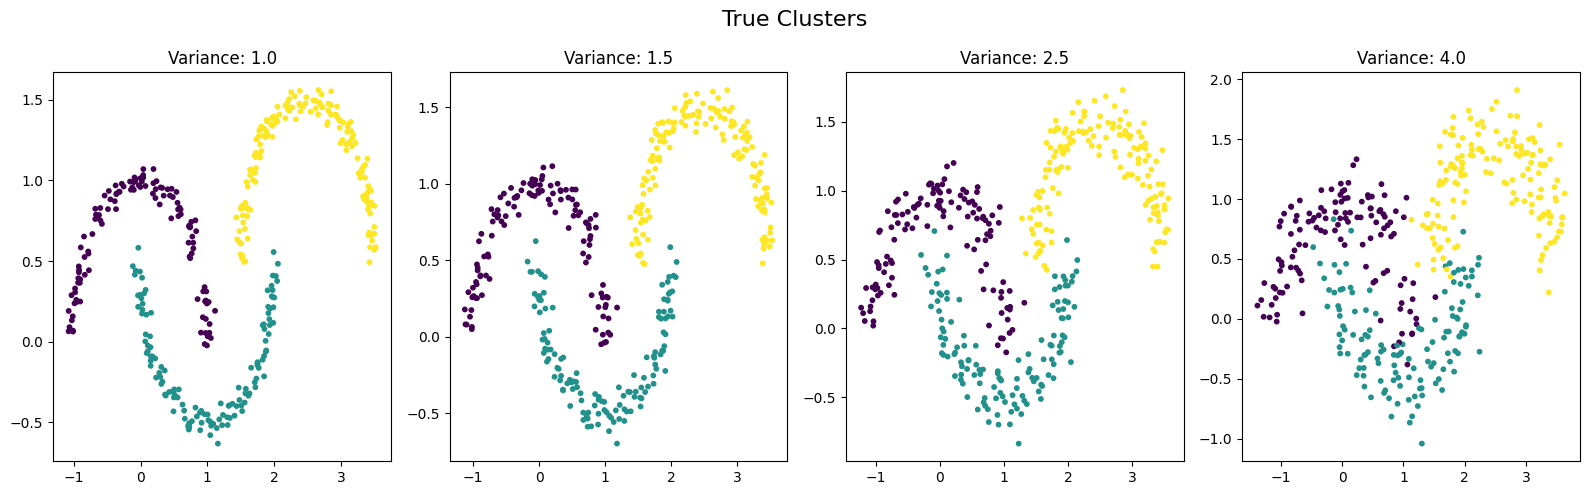

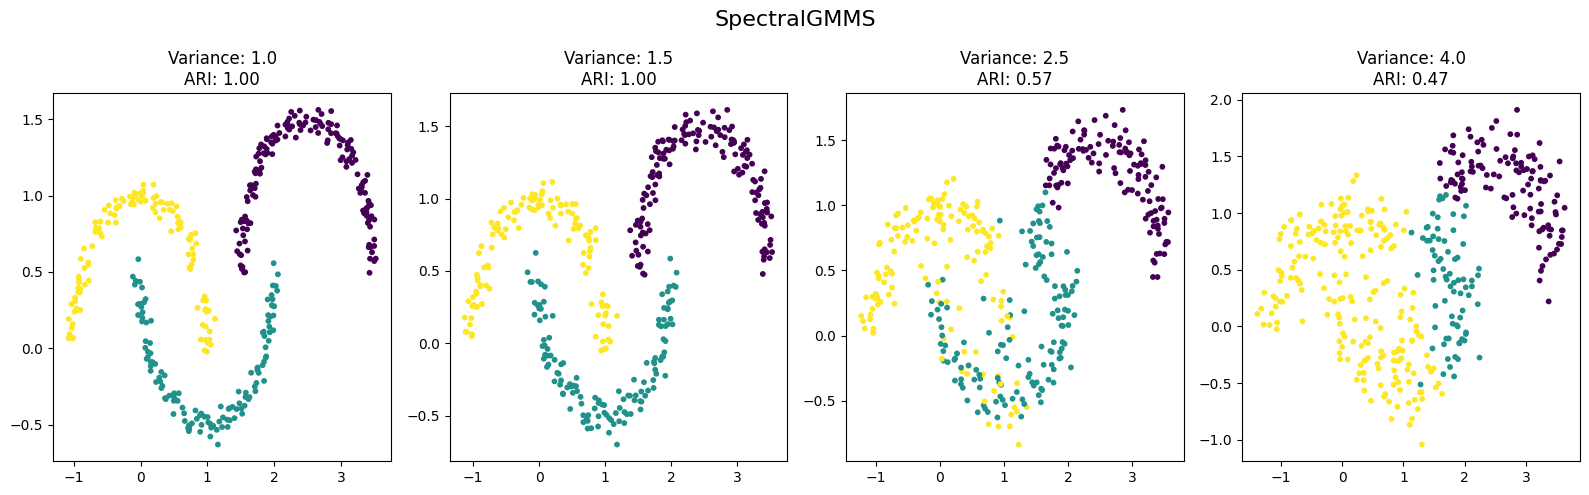

In [81]:
K = 3
n = 400
variance_range = [1.0, 1.5, 2.5, 4.0]
seed = 0
nn_frac = 0.04

fig, axes = plt.subplots(1, len(variance_range), figsize=(int(4*len(variance_range)), 5))
for ax, var in zip(axes, variance_range):
    X, y = gen_moons3(n_samples=n, noise=var*0.05, random_state=seed)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=10)
    ax.set_title(f'Variance: {var}')
fig.suptitle('True Clusters', fontsize=16)
plt.tight_layout()
plt.show()

# SpectralGMMS
fig, axes = plt.subplots(1, len(variance_range), figsize=(int(4*len(variance_range)), 5))
for ax, var in zip(axes, variance_range):
    X, y = gen_moons3(n_samples=n, noise=var*0.05, random_state=seed)
    sc = SpectralGMM(n_neighbors=int(n*nn_frac), n_components=K, random_state=seed)
    sc.fit(X)
    y_sc = soft_predict(sc.probs, seed=0)
    ari = adjusted_rand_score(y, y_sc)
    ax.scatter(X[:, 0], X[:, 1], c=y_sc, cmap='viridis', s=10)
    ax.set_title(f'Variance: {var}\nARI: {ari:.2f}')
fig.suptitle('SpectralGMMS', fontsize=16)
plt.tight_layout()
plt.show()

### **Fixed Sample Size**

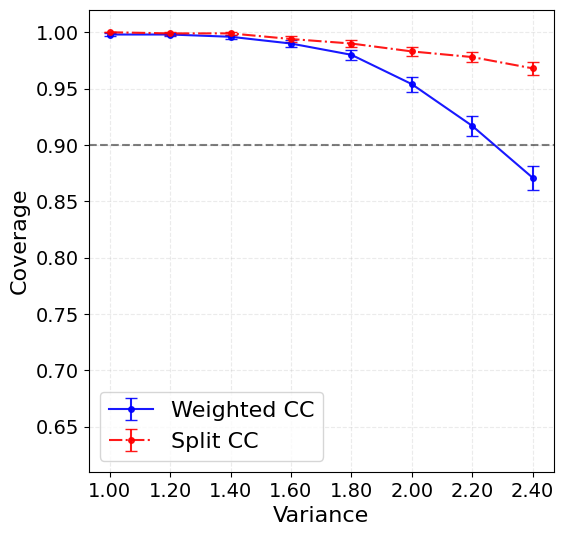

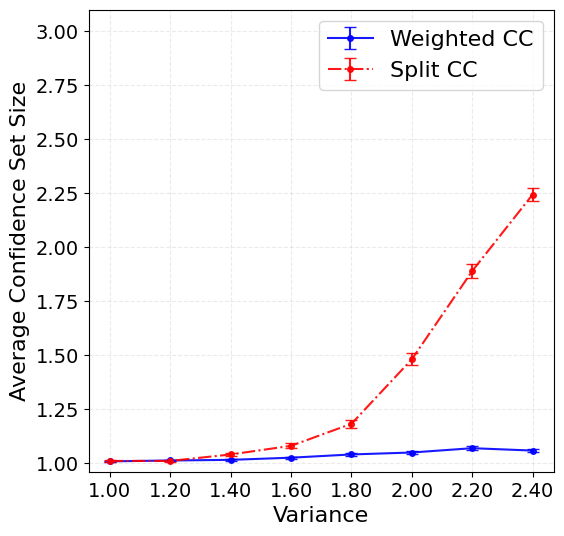

In [82]:
n = 600
B = 1000
var_range = np.linspace(1, 2.4, 8)

with open(f'Results/Moon2D3.pkl', 'rb') as f:
    results = pickle.load(f)

coverages = {'WeightedCC': [], 'SplitCC': []}
sizes = {'WeightedCC': [], 'SplitCC': []}

for method in ['WeightedCC', 'SplitCC']:
    cov, size = np.zeros((len(var_range), B)), np.zeros((len(var_range), B))
    for var_idx in range(len(var_range)):
        for b in range(B):
            res = results[var_idx*B + b]
            cov[var_idx, b], size[var_idx, b] = res[method]

    # Mean and standard error over B experiments
    cov_mean, cov_se = np.mean(cov, axis=1), np.std(cov, axis=1) / np.sqrt(B)
    size_mean, size_se = np.mean(size, axis=1), np.std(size, axis=1) / np.sqrt(B)

    # Store results for plotting
    coverages[method] = (cov_mean, cov_se)
    sizes[method] = (size_mean, size_se)


# Errorbars with connected lines (x-axis = sample size in log scale)
plt.figure(figsize=(6,6))
plt.errorbar(var_range, coverages['WeightedCC'][0], yerr=coverages['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
plt.errorbar(var_range, coverages['SplitCC'][0], yerr=coverages['SplitCC'][1], fmt='ro-.', capsize=4, markersize=4, alpha=0.9, label='Split CC')
plt.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
plt.xlabel('Variance', fontsize=16)
plt.xticks(ticks=var_range, labels=[f"{v:.2f}" for v in var_range], fontsize=14)
plt.ylabel('Coverage', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.61, 1.02))
plt.show()


plt.figure(figsize=(6,6))
plt.errorbar(var_range, sizes['WeightedCC'][0], yerr=sizes['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
plt.errorbar(var_range, sizes['SplitCC'][0], yerr=sizes['SplitCC'][1], fmt='ro-.', capsize=4, markersize=4, alpha=0.9, label='Split CC')
plt.xlabel('Variance', fontsize=16)
plt.xticks(ticks=var_range, labels=[f"{v:.2f}" for v in var_range], fontsize=14)
plt.ylabel('Average Confidence Set Size', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.96, 3.1))
plt.show()

### **Asymptotic: Increasing Sample Size**

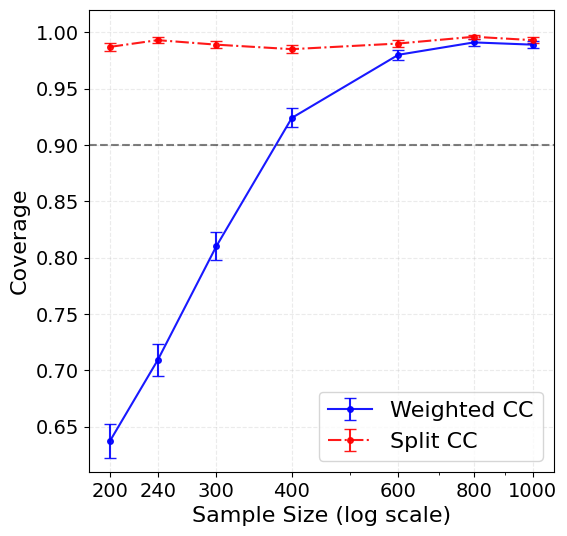

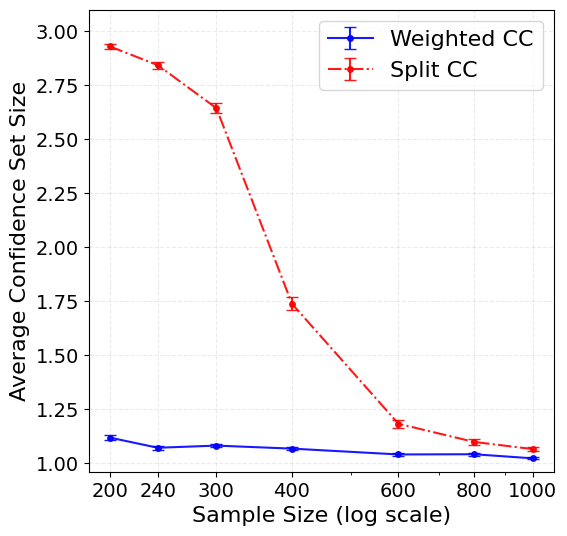

In [83]:
var = 1.8
B = 1000
n_range = [200, 240, 300, 400, 600, 800, 1000]

with open(f'Results/Moon2D3_asymp.pkl', 'rb') as f:
    results = pickle.load(f)

asymp_coverages = {'WeightedCC': [], 'SplitCC': []}
asymp_sizes = {'WeightedCC': [], 'SplitCC': []}

for method in ['WeightedCC', 'SplitCC']:
    cov, size = np.zeros((len(n_range), B)), np.zeros((len(n_range), B))
    for n_idx in range(len(n_range)):
        for b in range(B):
            res = results[n_idx*B + b]
            cov[n_idx, b], size[n_idx, b] = res[method]

    # Mean and standard error over B experiments
    cov_mean, cov_se = np.mean(cov, axis=1), np.std(cov, axis=1) / np.sqrt(B)
    size_mean, size_se = np.mean(size, axis=1), np.std(size, axis=1) / np.sqrt(B)

    # Store results for plotting
    asymp_coverages[method] = (cov_mean, cov_se)
    asymp_sizes[method] = (size_mean, size_se)
    

# Errorbars with connected lines (x-axis = sample size in log scale)
plt.figure(figsize=(6,6))
plt.errorbar(n_range, asymp_coverages['WeightedCC'][0], yerr=asymp_coverages['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
plt.errorbar(n_range, asymp_coverages['SplitCC'][0], yerr=asymp_coverages['SplitCC'][1], fmt='ro-.', capsize=4, markersize=4, alpha=0.9, label='Split CC')
plt.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
plt.xlabel('Sample Size (log scale)', fontsize=16)
plt.xscale('log')
plt.xticks(ticks=n_range, labels=[str(n) for n in n_range], fontsize=14)
plt.ylabel('Coverage', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.61, 1.02))
plt.show()


plt.figure(figsize=(6,6))
plt.errorbar(n_range, asymp_sizes['WeightedCC'][0], yerr=asymp_sizes['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
plt.errorbar(n_range, asymp_sizes['SplitCC'][0], yerr=asymp_sizes['SplitCC'][1], fmt='ro-.', capsize=4, markersize=4, alpha=0.9, label='Split CC')
plt.xlabel('Sample Size (log scale)', fontsize=16)
plt.xscale('log')
plt.xticks(ticks=n_range, labels=[str(n) for n in n_range], fontsize=14)
plt.ylabel('Average Confidence Set Size', fontsize=16)
plt.yticks(fontsize=14)
plt.legend(fontsize=16)
plt.grid(True, linestyle="--", alpha=0.25)
plt.ylim((0.96, 3.1))
plt.show()

### Combined Figures

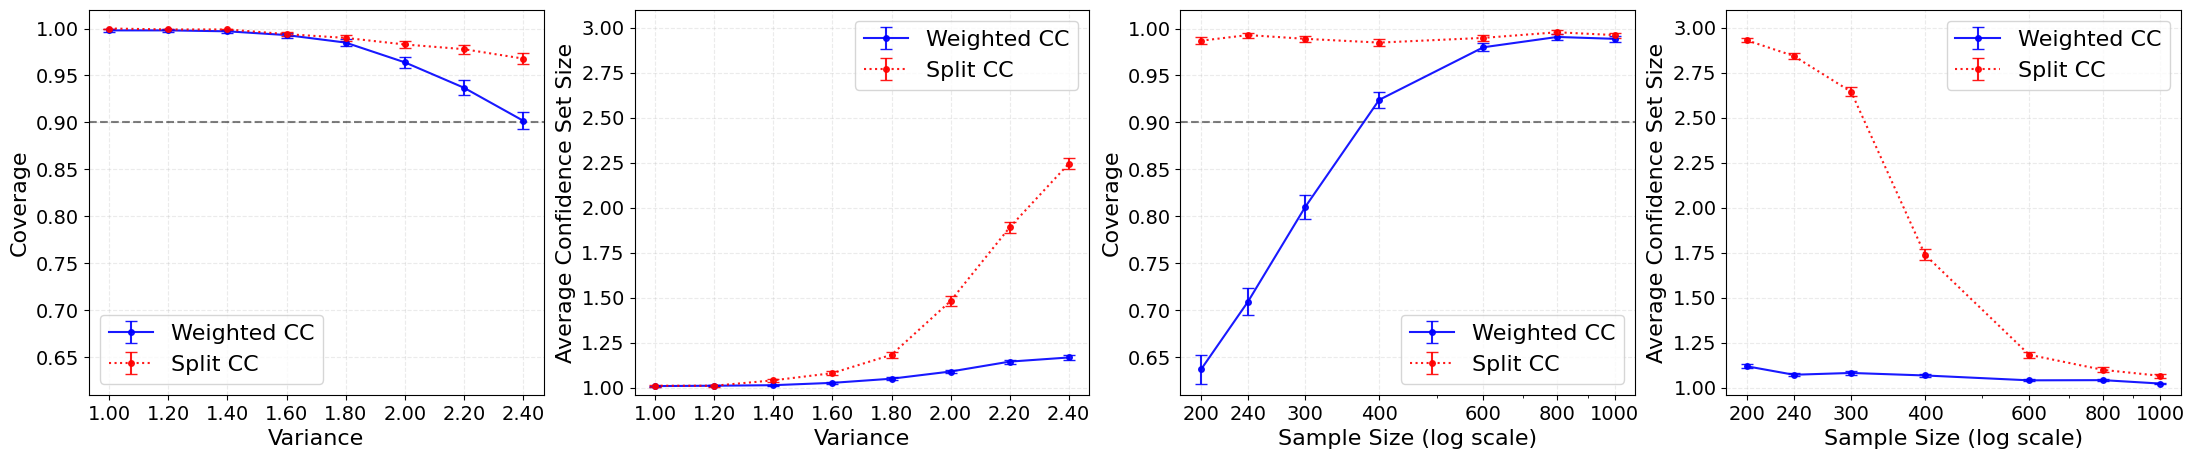

In [75]:
fig = plt.figure(figsize=(27, 5))
gs = GridSpec(nrows=1, ncols=4, figure=fig, wspace=0.2, hspace=0.2)

# Coverage (fixed sample size)
ax1 = fig.add_subplot(gs[0, 0])
ax1.errorbar(var_range, coverages['WeightedCC'][0], yerr=coverages['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
ax1.errorbar(var_range, coverages['SplitCC'][0], yerr=coverages['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
ax1.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
ax1.set_xlabel('Variance', fontsize=16)
ax1.set_xticks(var_range)
ax1.set_xticklabels(labels=[f"{v:.2f}" for v in var_range], fontsize=14)
ax1.set_ylabel('Coverage', fontsize=16)
ax1.tick_params(axis='y', labelsize=14)
ax1.legend(fontsize=16)
ax1.grid(True, linestyle="--", alpha=0.25)
ax1.set_ylim((0.61, 1.02))

# Size (fixed sample size)
ax2 = fig.add_subplot(gs[0, 1])
ax2.errorbar(var_range, sizes['WeightedCC'][0], yerr=sizes['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
ax2.errorbar(var_range, sizes['SplitCC'][0], yerr=sizes['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
ax2.set_xlabel('Variance', fontsize=16)
ax2.set_xticks(var_range)
ax2.set_xticklabels(labels=[f"{v:.2f}" for v in var_range], fontsize=14)
ax2.set_ylabel('Average Confidence Set Size', fontsize=16)
ax2.tick_params(axis='y', labelsize=14)
ax2.legend(fontsize=16)
ax2.grid(True, linestyle="--", alpha=0.25)
ax2.set_ylim((0.96, 3.1))

# Asymptotic coverage
ax3 = fig.add_subplot(gs[0, 2])
ax3.errorbar(n_range, asymp_coverages['WeightedCC'][0], yerr=asymp_coverages['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
ax3.errorbar(n_range, asymp_coverages['SplitCC'][0], yerr=asymp_coverages['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
ax3.axhline(y=0.9, color='k', linestyle='--', alpha=0.5)
ax3.set_xlabel('Sample Size (log scale)', fontsize=16)
ax3.set_xscale('log')
ax3.set_xticks(n_range)
ax3.set_xticklabels([str(n) for n in n_range], fontsize=14)
ax3.set_ylabel('Coverage', fontsize=16)
ax3.tick_params(axis='y', labelsize=14)
ax3.legend(fontsize=16)
ax3.grid(True, linestyle="--", alpha=0.25)
ax3.set_ylim((0.61, 1.02))

# Asymptotic size
ax4 = fig.add_subplot(gs[0, 3])
ax4.errorbar(n_range, asymp_sizes['WeightedCC'][0], yerr=asymp_sizes['WeightedCC'][1], fmt='bo-', capsize=4, markersize=4, alpha=0.9, label='Weighted CC')
ax4.errorbar(n_range, asymp_sizes['SplitCC'][0], yerr=asymp_sizes['SplitCC'][1], fmt='ro:', capsize=4, markersize=4, alpha=0.9, label='Split CC')
ax4.set_xlabel('Sample Size (log scale)', fontsize=16)
ax4.set_xscale('log')
ax4.set_xticks(n_range)
ax4.set_xticklabels([str(n) for n in n_range], fontsize=14)
ax4.set_ylabel('Average Confidence Set Size', fontsize=16)
ax4.tick_params(axis='y', labelsize=14)
ax4.legend(fontsize=16)
ax4.grid(True, linestyle="--", alpha=0.25)
ax4.set_ylim((0.96, 3.1))

plt.savefig('Figures/Moon2D3.pdf', bbox_inches='tight')
plt.show()

## **Heatmap**

In [76]:
# ---- Core colors (0..4) ----
core_hex = {
    3: "#B10DC9",  # purple
    1: "#FDFF8D",  # orange
    2: "#2ECC40",  # green
    0: "#FF810B",  # red
    4: "#64EDFF83",  # blue
}
core_rgb = {k: np.array(mcolors.to_rgb(v), float) for k, v in core_hex.items()}
# --- 6) Define dark colors for training points ---
def darken(rgb, factor=0.15):  # 0.15 = 15% darker
    return np.clip(rgb * (1 - factor), 0, 1)

dark_colors = {k: darken(core_rgb[k], 0.15) for k in core_rgb}


def lighten_toward_white(rgb, alpha):
    """alpha in [0,1]: 0 = no change, 1 = white."""
    return (1 - alpha) * rgb + alpha * 1.0

def labels_to_color(labels_like, n_classes=5, base_alpha=0.05):
    """
    - If labels_like is an int -> use that core color.
    - If it's an iterable -> take the mean of the cores in it,
      then 'intensify by number of labels' by moving toward white
      with alpha = base_alpha * (k-1), where k = set size.
      (More labels -> lighter background.)
    """
    # normalize to a Python set of ints
    if isinstance(labels_like, (int, np.integer)):
        S = {int(labels_like)}
    else:
        S = {int(x) for x in labels_like}

    # empty set -> white
    if len(S) == 0:
        return np.array([1.0, 1.0, 1.0], float)

    # mean of the present cores
    mean_rgb = np.mean([core_rgb[i] for i in S], axis=0)

    # intensity control by subset size k
    k = len(S)
    alpha = min(1.0, base_alpha * (k - 1))  # more labels -> lighter
    return lighten_toward_white(mean_rgb, alpha)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:    1.9s
[Parallel(n_jobs=-1)]: Done 890 tasks      | elapsed:    4.3s
[Parallel(n_jobs=-1)]: Done 2500 out of 2500 | elapsed:    8.6s finished


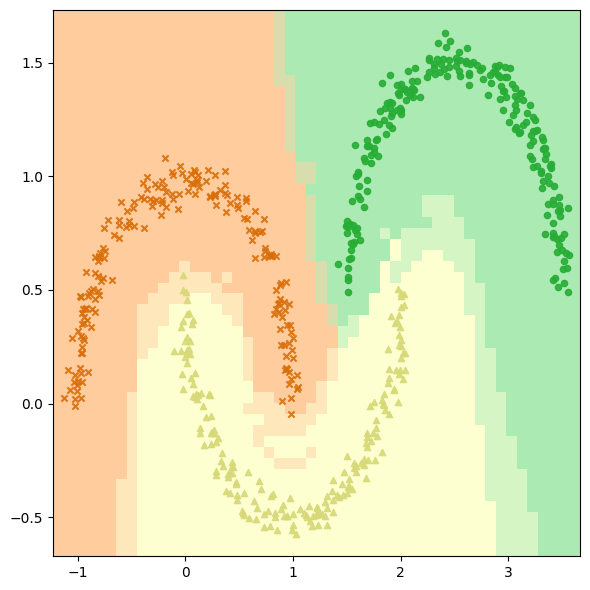

In [77]:
n = 600
var = 1.0
X, y = gen_moons3(n_samples=n, noise=var*0.05, random_state=0)
X_tr, y_tr = X[:(n//2)], y[:(n//2)] # training
X_cal, y_cal = X[(n//2):n], y[(n//2):n] # calibration
wcc = WeightedConformalClustering(X_tr, X_cal)
wcc.set_classifier('kNN', n_neighbors=int(np.sqrt(n//2/2)))
wcc.train('SpectralGMMS', n_neighbors=int(((n//2)+1)*0.05), n_components=K, random_state=0)

# ---- grid over the 2D plane (same for all methods) ---
x_min = X[:,0].min() - 0.1
x_max = X[:,0].max() + 0.1
y_min = X[:,1].min() - 0.1
y_max = X[:,1].max() + 0.1

res = 50
x_range = np.linspace(x_min, x_max, res)
y_range = np.linspace(y_min, y_max, res)
X_grid, Y_grid = np.meshgrid(x_range, y_range)
grid_points = np.column_stack((X_grid.ravel(), Y_grid.ravel())) # flattened grid points

# use joblib to apply wcc.conformal_set to all grid points in parallel
predictions_boolean = Parallel(n_jobs=-1, verbose=1)(
    delayed(wcc.conformal_set)(grid_points[i].reshape(1, -1), 'SpectralGMMS', n_neighbors=int(((n//2)+1)*0.05), n_components=K, random_state=0)
    for i in range(grid_points.shape[0])
)

oracle_alignment = label_alignment(y_tr, wcc.y_tr, K) # oracle alignment
color_grid = np.array([labels_to_color(oracle_alignment[predictions_boolean[i]]) for i in range(len(predictions_boolean))])
color_grid = color_grid.reshape((res, res, 3)) # reshape to grid

plt.figure(figsize=(6,6))
plt.imshow(
    color_grid,
    origin='lower',
    extent=(x_min, x_max, y_min, y_max),
    aspect='auto',
    alpha=0.4
)
for label in range(K):
    mask = (y == label)
    marker_size = 30
    if label == 0:
        marker = 'x'
    elif label == 1:
        marker = '^'
    else:
        marker = 'o'
        marker_size = 15
    plt.scatter(
        X[mask, 0],
        X[mask, 1],
        color=dark_colors[label],
        s=20,
        alpha=0.9, 
        marker=marker
    )
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)

plt.tight_layout()
plt.show()

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 1900 tasks      | elapsed:    4.4s
[Parallel(n_jobs=-1)]: Done 2500 out of 2500 | elapsed:    5.4s finished


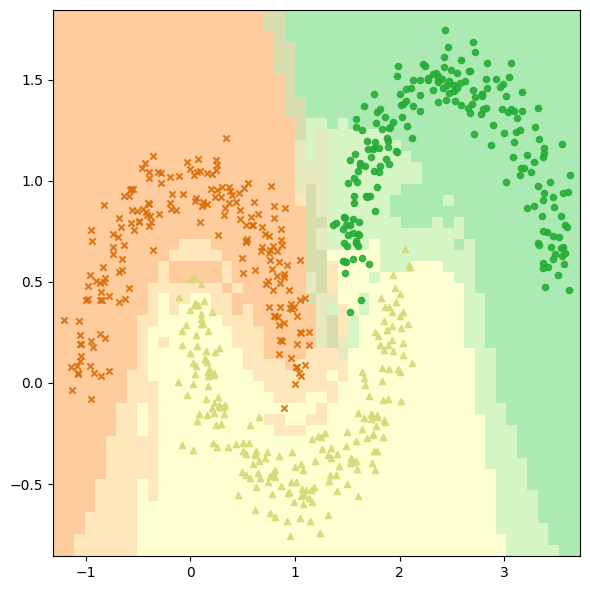

In [78]:
n = 600
var = 2.2
X, y = gen_moons3(n_samples=n, noise=var*0.05, random_state=9)
X_tr, y_tr = X[:(n//2)], y[:(n//2)] # training
X_cal, y_cal = X[(n//2):n], y[(n//2):n] # calibration
wcc = WeightedConformalClustering(X_tr, X_cal)
wcc.set_classifier('kNN', n_neighbors=int(np.sqrt(n//2/2)))
wcc.train('SpectralGMMS', n_neighbors=int(((n//2)+1)*0.05), n_components=K, random_state=2)

# ---- grid over the 2D plane (same for all methods) ---
x_min = X[:,0].min() - 0.1
x_max = X[:,0].max() + 0.1
y_min = X[:,1].min() - 0.1
y_max = X[:,1].max() + 0.1

res = 50
x_range = np.linspace(x_min, x_max, res)
y_range = np.linspace(y_min, y_max, res)
X_grid, Y_grid = np.meshgrid(x_range, y_range)
grid_points = np.column_stack((X_grid.ravel(), Y_grid.ravel())) # flattened grid points

# use joblib to apply wcc.conformal_set to all grid points in parallel
predictions_boolean = Parallel(n_jobs=-1, verbose=1)(
    delayed(wcc.conformal_set)(grid_points[i].reshape(1, -1), 'SpectralGMMS', n_neighbors=int(((n//2)+1)*0.05), n_components=K, random_state=2)
    for i in range(grid_points.shape[0])
)

oracle_alignment = label_alignment(y_tr, wcc.y_tr, K) # oracle alignment
color_grid = np.array([labels_to_color(oracle_alignment[predictions_boolean[i]]) for i in range(len(predictions_boolean))])
color_grid = color_grid.reshape((res, res, 3)) # reshape to grid

plt.figure(figsize=(6,6))
plt.imshow(
    color_grid,
    origin='lower',
    extent=(x_min, x_max, y_min, y_max),
    aspect='auto',
    alpha=0.4
)
for label in range(K):
    mask = (y == label)
    marker_size = 30
    if label == 0:
        marker = 'x'
    elif label == 1:
        marker = '^'
    else:
        marker = 'o'
        marker_size = 15
    plt.scatter(
        X[mask, 0],
        X[mask, 1],
        color=dark_colors[label],
        s=20,
        alpha=0.9, 
        marker=marker
    )
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)

plt.tight_layout()
plt.show()

### Combined Heatmaps

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1100 tasks      | elapsed:    2.7s
[Parallel(n_jobs=-1)]: Done 3100 tasks      | elapsed:    7.3s
[Parallel(n_jobs=-1)]: Done 5900 tasks      | elapsed:   13.9s
[Parallel(n_jobs=-1)]: Done 9500 tasks      | elapsed:   22.6s
[Parallel(n_jobs=-1)]: Done 13900 tasks      | elapsed:   33.0s
[Parallel(n_jobs=-1)]: Done 19100 tasks      | elapsed:   46.2s
[Parallel(n_jobs=-1)]: Done 25100 tasks      | elapsed:  1.0min
[Parallel(n_jobs=-1)]: Done 31900 tasks      | elapsed:  1.4min
[Parallel(n_jobs=-1)]: Done 39500 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done 40000 out of 40000 | elapsed:  1.8min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 1100 tasks      | elapsed:    3.6s
[Parallel(n_

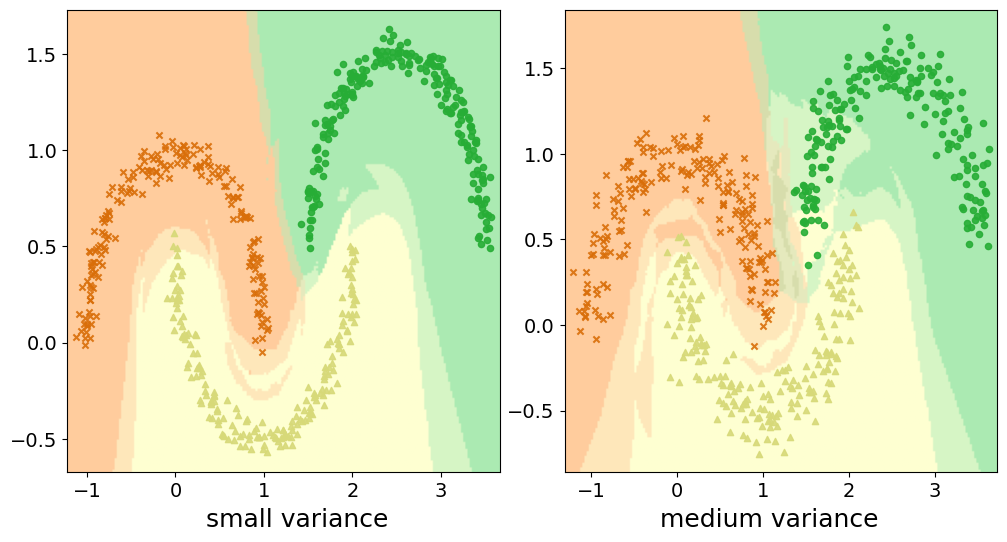

In [79]:
fig = plt.figure(figsize=(12, 6))
gs = GridSpec(nrows=1, ncols=2, figure=fig, wspace=0.15, hspace=0.2)

# Heatmap 1
ax1 = fig.add_subplot(gs[0, 0])
n = 600
var = 1.0
X, y = gen_moons3(n_samples=n, noise=var*0.05, random_state=0)
X_tr, y_tr = X[:(n//2)], y[:(n//2)] # training
X_cal, y_cal = X[(n//2):n], y[(n//2):n] # calibration
wcc = WeightedConformalClustering(X_tr, X_cal)
wcc.set_classifier('kNN', n_neighbors=int(np.sqrt(n//2/2)))
wcc.train('SpectralGMMS', n_neighbors=int(((n//2)+1)*0.05), n_components=K, random_state=0)

# ---- grid over the 2D plane (same for all methods) ---
x_min = X[:,0].min() - 0.1
x_max = X[:,0].max() + 0.1
y_min = X[:,1].min() - 0.1
y_max = X[:,1].max() + 0.1

res = 200
x_range = np.linspace(x_min, x_max, res)
y_range = np.linspace(y_min, y_max, res)
X_grid, Y_grid = np.meshgrid(x_range, y_range)
grid_points = np.column_stack((X_grid.ravel(), Y_grid.ravel())) # flattened grid points

# use joblib to apply wcc.conformal_set to all grid points in parallel
predictions_boolean = Parallel(n_jobs=-1, verbose=1)(
    delayed(wcc.conformal_set)(grid_points[i].reshape(1, -1), 'SpectralGMMS', n_neighbors=int(((n//2)+1)*0.05), n_components=K, random_state=0)
    for i in range(grid_points.shape[0])
)

oracle_alignment = label_alignment(y_tr, wcc.y_tr, K) # oracle alignment
color_grid = np.array([labels_to_color(oracle_alignment[predictions_boolean[i]]) for i in range(len(predictions_boolean))])
color_grid = color_grid.reshape((res, res, 3)) # reshape to grid

ax1.imshow(
    color_grid,
    origin='lower',
    extent=(x_min, x_max, y_min, y_max),
    aspect='auto',
    alpha=0.4
)
for label in range(K):
    mask = (y == label)
    marker_size = 30
    if label == 0:
        marker = 'x'
    elif label == 1:
        marker = '^'
    else:
        marker = 'o'
        marker_size = 15
    ax1.scatter(
        X[mask, 0],
        X[mask, 1],
        color=dark_colors[label],
        s=20,
        alpha=0.9, 
        marker=marker
    )
ax1.set_xlim(x_min, x_max)
ax1.set_ylim(y_min, y_max)
ax1.tick_params(axis='x', labelsize=14)
ax1.tick_params(axis='y', labelsize=14)


# Heatmap 2
ax2 = fig.add_subplot(gs[0, 1])
n = 600
var = 2.2
X, y = gen_moons3(n_samples=n, noise=var*0.05, random_state=9)
X_tr, y_tr = X[:(n//2)], y[:(n//2)] # training
X_cal, y_cal = X[(n//2):n], y[(n//2):n] # calibration
wcc = WeightedConformalClustering(X_tr, X_cal)
wcc.set_classifier('kNN', n_neighbors=int(np.sqrt(n//2/2)))
wcc.train('SpectralGMMS', n_neighbors=int(((n//2)+1)*0.05), n_components=K, random_state=2)

# ---- grid over the 2D plane (same for all methods) ---
x_min = X[:,0].min() - 0.1
x_max = X[:,0].max() + 0.1
y_min = X[:,1].min() - 0.1
y_max = X[:,1].max() + 0.1

res = 200
x_range = np.linspace(x_min, x_max, res)
y_range = np.linspace(y_min, y_max, res)
X_grid, Y_grid = np.meshgrid(x_range, y_range)
grid_points = np.column_stack((X_grid.ravel(), Y_grid.ravel())) # flattened grid points

# use joblib to apply wcc.conformal_set to all grid points in parallel
predictions_boolean = Parallel(n_jobs=-1, verbose=1)(
    delayed(wcc.conformal_set)(grid_points[i].reshape(1, -1), 'SpectralGMMS', n_neighbors=int(((n//2)+1)*0.05), n_components=K, random_state=2)
    for i in range(grid_points.shape[0])
)

oracle_alignment = label_alignment(y_tr, wcc.y_tr, K) # oracle alignment
color_grid = np.array([labels_to_color(oracle_alignment[predictions_boolean[i]]) for i in range(len(predictions_boolean))])
color_grid = color_grid.reshape((res, res, 3)) # reshape to grid

ax2.imshow(
    color_grid,
    origin='lower',
    extent=(x_min, x_max, y_min, y_max),
    aspect='auto',
    alpha=0.4
)
for label in range(K):
    mask = (y == label)
    marker_size = 30
    if label == 0:
        marker = 'x'
    elif label == 1:
        marker = '^'
    else:
        marker = 'o'
        marker_size = 15
    ax2.scatter(
        X[mask, 0],
        X[mask, 1],
        color=dark_colors[label],
        s=20,
        alpha=0.9, 
        marker=marker
    )
ax2.set_xlim(x_min, x_max)
ax2.set_ylim(y_min, y_max)
ax2.tick_params(axis='x', labelsize=14)
ax2.tick_params(axis='y', labelsize=14)

ax1.annotate('small variance', xy=(0.32, -0.12), xycoords='axes fraction', fontsize=18, color='black')
ax2.annotate('medium variance', xy=(0.22, -0.12), xycoords='axes fraction', fontsize=18, color='black')

plt.savefig('Figures/Moon2D3_heatmaps.pdf', bbox_inches='tight')
plt.show()